# Лабораторная работа № 1
## Иерархическая кластеризация


## Импорт библиотек


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from IPython.display import display


## Подготовка данных


In [ ]:
# Загружаем исходную таблицу и отмечаем пропуски.
DATA_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/lab1/Econom_Cities_data.csv"
raw = pd.read_csv(DATA_URL, sep=';', decimal=',', na_values=[-9999])
features = ['Work', 'Price', 'Salary']

display(raw.head())

# Показываем города с неполными данными.
display(raw.loc[raw[features].isna().any(axis=1)])

# Запоминаем исключённые города и удаляем неполные строки.
excluded = raw.loc[raw[features].isna().any(axis=1), 'City'].tolist()
df = raw.dropna(subset=features).copy().reset_index(drop=True)

# Приводим три признака к одному масштабу.
X = StandardScaler().fit_transform(df[features])
print(f'Исходно: {len(raw)} городов; в анализе: {len(df)}; исключены: {excluded}')

display(df[features].describe().round(2))


,City,Work,Price,Salary
0,Amsterdam,1714.0,65.6,49.0
1,Athens,1792.0,53.8,30.4
2,Bogota,2152.0,37.9,11.5
3,Bombay,2052.0,30.3,5.3
4,Brussels,1708.0,73.8,50.5


,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


Исходно: 48 городов; в анализе: 46; исключены: ['Cairo', 'Jakarta']


,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


In [ ]:
# Загружаем показатели стран за 1991 год и сопоставляем города со странами.
COUNTRIES_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/countries_1991.csv"
country_indicators = pd.read_csv(COUNTRIES_URL)
city_country = {
    'Amsterdam': 'Нидерланды',
    'Athens': 'Греция',
    'Bogota': 'Колумбия',
    'Bombay': 'Индия',
    'Brussels': 'Бельгия',
    'Buenos_Aires': 'Аргентина',
    'Cairo': 'Египет',
    'Caracas': 'Венесуэла',
    'Chicago': 'США',
    'Copenhagen': 'Дания',
    'Dublin': 'Ирландия',
    'Dusseldorf': 'Германия',
    'Frankfurt': 'Германия',
    'Geneva': 'Швейцария',
    'Helsinki': 'Финляндия',
    'Hong_Kong': 'Гонконг',
    'Houston': 'США',
    'Jakarta': 'Индонезия',
    'Johannesburg': 'ЮАР',
    'Kuala_Lumpur': 'Малайзия',
    'Lagos': 'Нигерия',
    'Lisbon': 'Португалия',
    'London': 'Великобритания',
    'Los_Angeles': 'США',
    'Luxembourg': 'Люксембург',
    'Madrid': 'Испания',
    'Manila': 'Филиппины',
    'Mexico_City': 'Мексика',
    'Milan': 'Италия',
    'Montreal': 'Канада',
    'Nairobi': 'Кения',
    'New_York': 'США',
    'Nicosia': 'Кипр',
    'Oslo': 'Норвегия',
    'Panama': 'Панама',
    'Paris': 'Франция',
    'Rio_de_Janeiro': 'Бразилия',
    'San_Paulo': 'Бразилия',
    'Seoul': 'Южная Корея',
    'Singpore': 'Сингапур',
    'Stockholm': 'Швеция',
    'Sydney': 'Австралия',
    'Taipei': 'Тайвань',
    'Tel_Aviv': 'Израиль',
    'Tokyo': 'Япония',
    'Toronto': 'Канада',
    'Vienna': 'Австрия',
    'Zurich': 'Швейцария',
}
external_features = ['HDI', 'Life_expectancy']


# Присоединяем национальные показатели к городам.
def attach_country_indicators(city_data):
    external = city_data[['City']].copy()
    external['Country'] = external.City.map(city_country)
    return external.merge(country_indicators, on='Country', how='left',
                          validate='many_to_one', sort=False)


def compare_living_standards(city_data, cluster_labels, title, plots=True):
    # Присоединяем показатели стран к готовым назначениям городов.
    external = attach_country_indicators(city_data)
    external['Group'] = np.asarray(cluster_labels)
    complete = external.dropna(subset=external_features)
    clustered = complete.loc[complete.Group.ne(-1)].copy()
    print(title)
    print(f'Городов с двумя показателями: {len(complete)}/{len(external)}; '
          f'в кластерах: {len(clustered)}; шум с показателями: {complete.Group.eq(-1).sum()}')

    # Выводим средние, медианы и диапазоны показателей внутри групп.
    summary = complete.groupby('Group').agg(
        Cities=('City', 'size'), Countries=('Country', 'nunique'),
        HDI_mean=('HDI', 'mean'), HDI_median=('HDI', 'median'),
        HDI_min=('HDI', 'min'), HDI_max=('HDI', 'max'),
        Life_mean=('Life_expectancy', 'mean'),
        Life_median=('Life_expectancy', 'median'),
        Life_min=('Life_expectancy', 'min'), Life_max=('Life_expectancy', 'max'))
    summary.index = ['Шум' if g == -1 else f'Кластер {g}' for g in summary.index]
    display(summary.round(3))

    # Считаем долю различий, приходящуюся на различия между группами.
    def between_group_share(feature, weights):
        if clustered.Group.nunique() < 2:
            return np.nan
        overall = np.average(clustered[feature], weights=weights)
        total = np.sum(weights * (clustered[feature] - overall) ** 2)
        between = 0.0
        for _, group in clustered.groupby('Group'):
            group_weights = weights.loc[group.index]
            mean = np.average(group[feature], weights=group_weights)
            between += group_weights.sum() * (mean - overall) ** 2
        return between / total if total > 0 else np.nan

    # Повторяем оценку, уравнивая суммарный вес каждой страны.
    weights_city = pd.Series(1.0, index=clustered.index)
    weights_country = 1 / clustered.groupby('Country').City.transform('size')
    result = {'Городов в оценке': len(clustered),
              'Стран в оценке': clustered.Country.nunique()}
    for feature, name in [('HDI', 'ИЧР'), ('Life_expectancy', 'Продолжительность жизни')]:
        result[f'η²: {name}'] = between_group_share(feature, weights_city)
        result[f'η²: {name}, равный вес стран'] = between_group_share(feature, weights_country)

    if plots:
        # Показываем разброс показателей и расположение готовых групп.
        groups = sorted(complete.Group.unique(), key=lambda g: (g == -1, g))
        names = ['Шум' if g == -1 else f'Кластер {g}' for g in groups]
        fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
        for ax, feature, ylabel in [
            (axes[0], 'HDI', 'ИЧР'),
            (axes[1], 'Life_expectancy', 'Продолжительность жизни, лет')
        ]:
            ax.boxplot([complete.loc[complete.Group.eq(g), feature] for g in groups],
                       showfliers=False)
            ax.set_xticks(range(1, len(names) + 1))
            ax.set_xticklabels(names)
            for position, group in enumerate(groups, start=1):
                values = complete.loc[complete.Group.eq(group), feature].to_numpy()
                offsets = np.linspace(-.10, .10, len(values))
                ax.scatter(position + offsets, values, alpha=.65, s=26)
            ax.set(title=ylabel + ' по группам', ylabel=ylabel)
            ax.tick_params(axis='x', labelrotation=20)
            ax.grid(axis='y', alpha=.2)
        for group, name in zip(groups, names):
            part = complete.loc[complete.Group.eq(group)]
            axes[2].scatter(part.HDI, part.Life_expectancy,
                            label=name, marker='^' if group == -1 else 'o', alpha=.75)
        centers = clustered.groupby('Group')[external_features].mean()
        axes[2].scatter(centers.HDI, centers.Life_expectancy, marker='x', c='black',
                        s=120, linewidths=2, label='Средние показатели групп', zorder=5)
        axes[2].set(title='Группы по сторонним показателям', xlabel='ИЧР',
                    ylabel='Продолжительность жизни, лет')
        axes[2].legend()
        axes[2].grid(alpha=.2)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()
    return result


## Вспомогательные функции


In [ ]:
# Выводим размеры, средние признаки и состав групп.
def show_cluster_summary(data, cluster_column, features, medians=False,
                         assignments=True, mean_suffix='', decimals=2):
    grouped = data.groupby(cluster_column)
    summary = grouped.agg(Cities=('City', 'size'),
                          **{feature + mean_suffix: (feature, 'mean') for feature in features})
    display(summary.round(decimals))
    if medians:
        display(grouped[features].median().round(decimals)
                .rename_axis(cluster_column + ': medians'))
    for cluster, group in grouped:
        name = 'Шум' if cluster == -1 else f'Кластер {cluster}'
        print(f'{name} ({len(group)} городов):',
              ', '.join(group.City.str.replace('_', ' ').sort_values()))
    if assignments:
        display(data.sort_values([cluster_column, 'City']).reset_index(drop=True))
    return summary


# Строим профили групп и все три парные диаграммы.
def plot_cluster_profiles(data, points, group_labels, features, title):
    plot_data = data.assign(Group=np.asarray(group_labels))
    clustered = plot_data.loc[plot_data.Group.ne(-1)]
    noise = plot_data.loc[plot_data.Group.eq(-1)]
    profiles = (pd.DataFrame(points, columns=features).assign(Group=np.asarray(group_labels))
                .loc[np.asarray(group_labels) != -1].groupby('Group').mean())
    centers = clustered.groupby('Group')[features].mean()
    axis_names = {'Work': 'Рабочее время, часов в год',
                  'Price': 'Индекс цен', 'Salary': 'Индекс почасовой зарплаты'}
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    axes = axes.ravel()
    profiles.T.plot.bar(ax=axes[0], rot=0)
    axes[0].axhline(0, linewidth=1)
    axes[0].set(title=title + ': стандартизированные средние', ylabel='Средний z-балл')
    axes[0].legend(title='Кластер')
    for ax, x, y, pair_title in [
        (axes[1], 'Price', 'Salary', 'Цены и зарплаты'),
        (axes[2], 'Work', 'Salary', 'Рабочее время и зарплата'),
        (axes[3], 'Work', 'Price', 'Рабочее время и цены')
    ]:
        for cluster, group in clustered.groupby('Group'):
            ax.scatter(group[x], group[y], s=55, alpha=.8,
                       label=f'Кластер {cluster} (n={len(group)})')
        if len(noise):
            ax.scatter(noise[x], noise[y], marker='^', s=75, label=f'Шум (n={len(noise)})')
        ax.scatter(centers[x], centers[y], marker='x', c='black', s=130,
                   linewidths=2, zorder=5, label='Центры кластеров')
        ax.set(title=title + ': ' + pair_title.lower(),
               xlabel=axis_names[x], ylabel=axis_names[y])
        ax.legend()
        ax.grid(alpha=.2)
    plt.tight_layout()
    plt.show()


# Исключаем по одному городу, повторяем разбиение и сравниваем назначения.
def check_leave_one_out(data, features, baseline, fit_labels):
    rows = []
    baseline = np.asarray(baseline)
    for i in range(len(data)):
        mask = np.arange(len(data)) != i
        points = StandardScaler().fit_transform(data.loc[mask, features])
        other = fit_labels(points)
        rows.append({'Excluded_city': data.iloc[i].City,
                     'ARI': adjusted_rand_score(baseline[mask], other)})
    return pd.DataFrame(rows)


### Выбор числа кластеров


method,average,complete,single,ward
k,,,,
2,0.4705,0.4705,0.2869,0.4705
3,0.4197,0.3875,0.0250,0.3612
4,0.3718,0.3658,0.0796,0.3551
5,0.3813,0.3795,0.0099,0.3475
6,0.3831,0.3905,0.0626,0.3657
7,0.3503,0.3953,0.0522,0.3959
8,0.3544,0.3932,0.3073,0.3990


,k,silhouette,min_size,sizes
0,2,0.4705,21,"25, 21"
1,3,0.3612,7,"25, 7, 14"
2,4,0.3551,6,"19, 7, 14, 6"
3,5,0.3475,5,"14, 7, 14, 5, 6"
4,6,0.3657,2,"14, 7, 12, 5, 6, 2"
5,7,0.3959,2,"14, 7, 12, 5, 2, 4, 2"
6,8,0.3990,2,"14, 7, 5, 7, 5, 2, 4, 2"


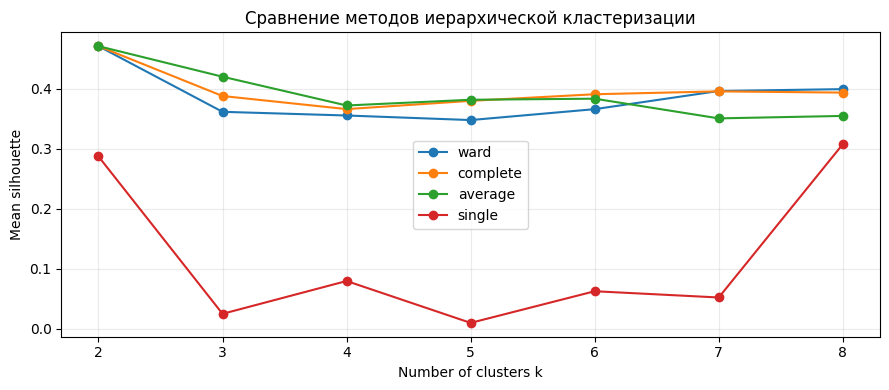

Выбрано k = 2; silhouette = 0.4705
Высота предпоследнего и последнего объединений: [ 5.0611 12.4003]


In [ ]:
# Сравниваем разбиения на 2–8 групп при разных способах объединения.
methods = ['ward', 'complete', 'average', 'single']
ks = range(2, 9)
links = {m: linkage(X, method=m, metric='euclidean') for m in methods}
rows = []
for method in methods:
    for k in ks:
        labels = cut_tree(links[method], n_clusters=k).ravel()
        sizes = np.bincount(labels)
        rows.append({'method': method, 'k': k,
                     'silhouette': silhouette_score(X, labels),
                     'min_size': sizes.min(), 'sizes': ', '.join(map(str, sizes))})
# Сводим оценки качества и размеры групп в таблицы и график.
scores = pd.DataFrame(rows)
display(scores.pivot(index='k', columns='method', values='silhouette').round(4))
display(scores.loc[scores.method.eq('ward'), ['k', 'silhouette', 'min_size', 'sizes']].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
for method in methods:
    part = scores[scores.method.eq(method)]
    ax.plot(part.k, part.silhouette, marker='o', label=method)
ax.set(xlabel='Number of clusters k', ylabel='Mean silhouette',
       title='Сравнение методов иерархической кластеризации', xticks=list(ks))
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

# Выбираем число групп по наибольшему силуэту и записываем назначения городов.
best_k = int(scores.loc[scores.method.eq('ward')].sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0]['k'])
Z = links['ward']
labels = cut_tree(Z, n_clusters=best_k).ravel() + 1
df['Cluster'] = labels
print(f'Выбрано k = {best_k}; silhouette = {silhouette_score(X, labels):.4f}')
print('Высота предпоследнего и последнего объединений:', np.round(Z[-2:, 2], 4))


### Обоснование решения

Выбраны **Ward и 2 кластера**. Силуэт — **0,4705**. Complete и average при двух группах дают то же разбиение. Получаются группы 25 и 21 город

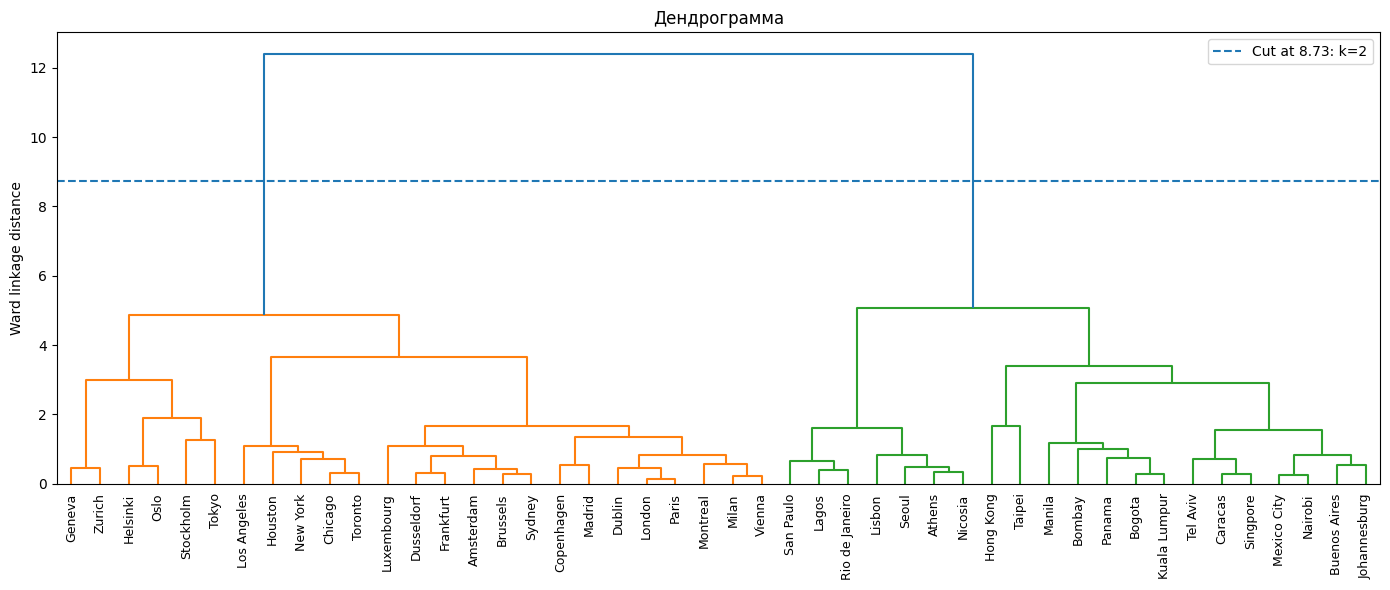

In [ ]:
# Строим дендрограмму и отмечаем разрез на две группы.
cut_height = (Z[-2, 2] + Z[-1, 2]) / 2
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, labels=df.City.str.replace('_', ' ').tolist(),
           leaf_rotation=90, leaf_font_size=9, color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, linestyle='--', label=f'Cut at {cut_height:.2f}: k={best_k}')
ax.set(title='Дендрограмма', ylabel='Ward linkage distance')
ax.legend(); plt.tight_layout(); plt.show()


### Состав и профили кластеров


,Cities,Work_mean,Price_mean,Salary_mean
Cluster,,,,
1,25,1789.24,84.97,59.03
2,21,1987.86,52.40,16.35


,Work,Price,Salary
Cluster: medians,,,
1,1768.0,79.8,58.2
2,1971.0,49.8,12.5


Кластер 1 (25 городов): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2 (21 городов): Athens, Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Taipei, Tel Aviv


,City,Work,Price,Salary,Cluster
0,Amsterdam,1714.0,65.6,49.0,1
1,Brussels,1708.0,73.8,50.5,1
2,Chicago,1924.0,73.9,61.9,1
3,Copenhagen,1717.0,91.3,62.9,1
4,Dublin,1759.0,76.0,41.4,1
5,Dusseldorf,1693.0,78.5,60.2,1
6,Frankfurt,1650.0,74.5,60.4,1
7,Geneva,1880.0,95.9,90.3,1
8,Helsinki,1667.0,113.6,66.6,1
9,Houston,1978.0,71.9,46.3,1


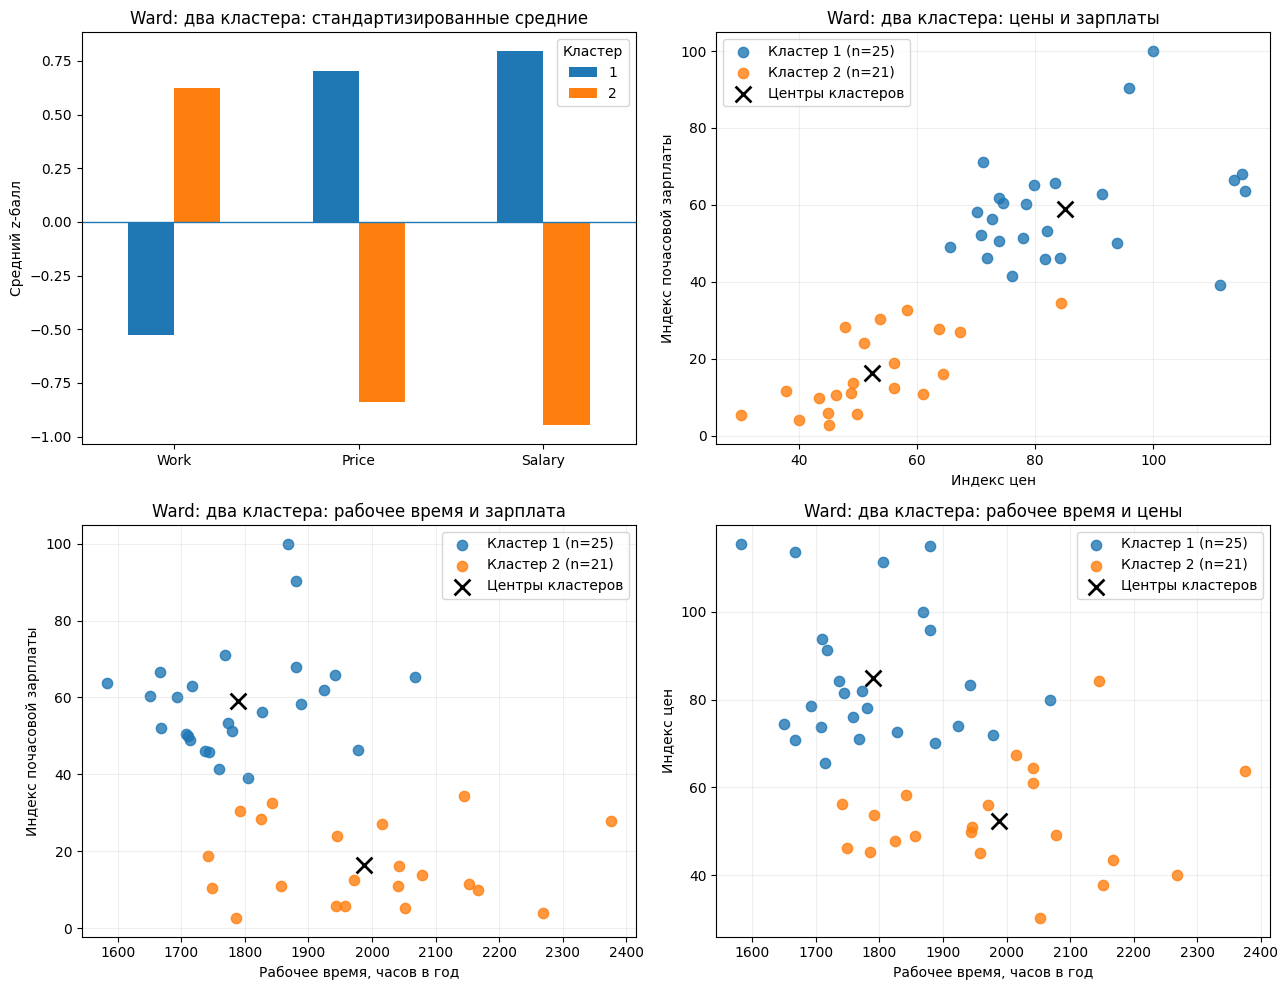

In [ ]:
# Показываем состав групп, их средние признаки и медианы.
profile = df.groupby('Cluster')[features].mean()
summary = show_cluster_summary(df, 'Cluster', features, medians=True, mean_suffix='_mean')
plot_cluster_profiles(df, X, df.Cluster.to_numpy(), features, 'Ward: два кластера')


### Экономическая интерпретация

| Кластер | Число городов | Среднее Work | Среднее Price | Среднее Salary | Интерпретация |
|---|---:|---:|---:|---:|---|
| 1 | 25 | 1789,24 | 84,97 | 59,03 | Более высокие цены и почасовые зарплаты, меньшее рабочее время |
| 2 | 21 | 1987,86 | 52,40 | 16,35 | Более низкие цены и почасовые зарплаты, большее рабочее время |

**Кластер 1.** Например, Лондон, Нью-Йорк, Токио. Кластер с большей почасовой оплатой и более высокими ценами при чуть меньшем количестве рабочих часов в год

**Кластер 2.** Например, Афины, Сеул, Мехико. ЗП и цены ниже, рабоают немного больше


### Насколько уверенно города попали в свои группы?

Силуэт около 1 означает хорошее разделение, около 0 — размытую границу. Отрицательное значение означает, что среднее расстояние до другой группы меньше, чем до своей. Это диагностика разбиения, а не вероятность правильного назначения.


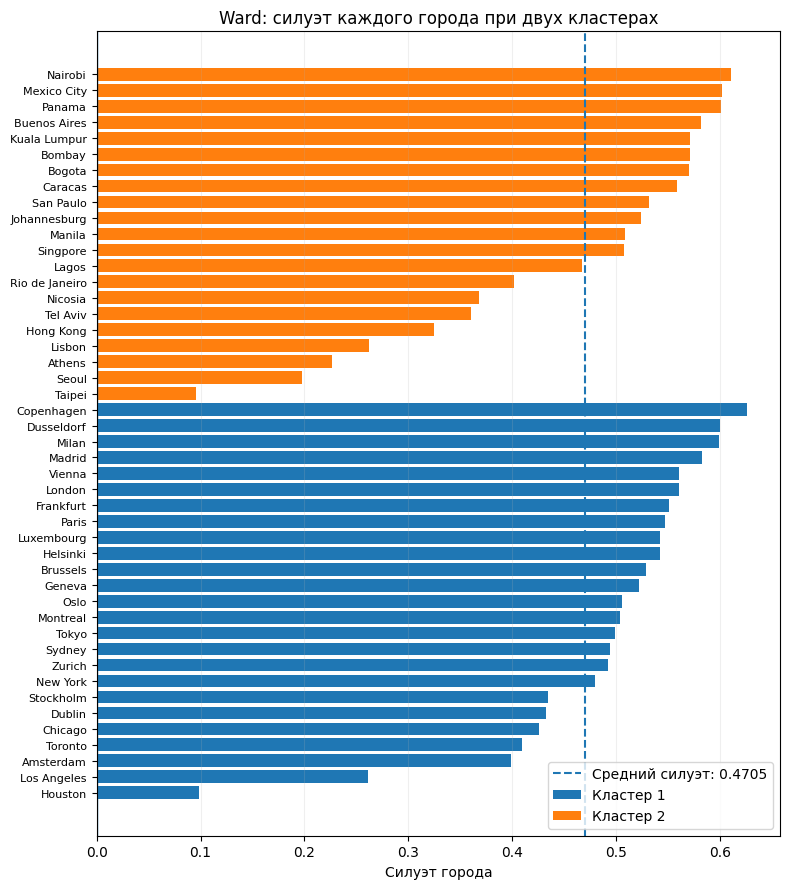

Городов с отрицательным силуэтом: 0
Города с силуэтом ниже 0,25:


,Город,Кластер,Силуэт
25,Taipei,2,0.0952
0,Houston,1,0.0985
26,Seoul,2,0.1975
27,Athens,2,0.2265


In [ ]:
# Считаем силуэт каждого города и сортируем города внутри групп.
def show_city_silhouette(points, labels, city_names, title):
    values = silhouette_samples(points, labels)
    table = pd.DataFrame({'Город': np.asarray(city_names),
                          'Кластер': labels, 'Силуэт': values})
    table = table.sort_values(['Кластер', 'Силуэт']).reset_index(drop=True)
    # Строим график силуэтов городов.
    fig, ax = plt.subplots(figsize=(8, 9))
    for cluster, part in table.groupby('Кластер'):
        ax.barh(part.index, part['Силуэт'], label=f'Кластер {cluster}')
    ax.set_yticks(table.index, table['Город'].str.replace('_', ' '), fontsize=8)
    ax.axvline(0, linewidth=1)
    ax.axvline(values.mean(), linestyle='--', label=f'Средний силуэт: {values.mean():.4f}')
    ax.set(title=title, xlabel='Силуэт города')
    ax.legend()
    ax.grid(axis='x', alpha=.2)
    plt.tight_layout()
    plt.show()
    # Выводим города с низкими и отрицательными силуэтами.
    print('Городов с отрицательным силуэтом:', int((values < 0).sum()))
    print('Города с силуэтом ниже 0,25:')
    display(table.loc[table['Силуэт'] < .25].sort_values('Силуэт').round(4))

show_city_silhouette(X, labels, df.City, 'Ward: силуэт каждого города при двух кластерах')


При двух группах отрицательных силуэтов нет. Ближе к границе находятся Тайбэй, Хьюстон, Сеул и Афины; у Тайбэя и Хьюстона силуэт около 0,10. Это показывает, что даже у выбранного разбиения есть менее уверенно отделённые города.


## Проверка чувствительности при двух кластерах


In [ ]:
# Сравниваем состав групп при смене способа объединения.
agreement = []
for method in methods:
    other = cut_tree(links[method], n_clusters=best_k).ravel()
    agreement.append({'method': method, 'ARI_vs_Ward': adjusted_rand_score(labels, other)})
display(pd.DataFrame(agreement).round(4))

# Заполняем пропуски медианами и повторно строим группы.
filled = raw.copy()
filled[features] = filled[features].fillna(filled[features].median())
X_filled = StandardScaler().fit_transform(filled[features])
Z_filled = linkage(X_filled, method='ward')
filled['Cluster_imputed'] = cut_tree(Z_filled, n_clusters=best_k).ravel()
common = df[['City', 'Cluster']].merge(filled[['City', 'Cluster_imputed']], on='City', validate='one_to_one')
imputation_ari = adjusted_rand_score(common.Cluster, common.Cluster_imputed)
print(f'ARI на 46 полных городах после медианного заполнения: {imputation_ari:.4f}')

# По очереди исключаем каждый город и сравниваем полученные разбиения.
loo = check_leave_one_out(
    df, features, labels,
    lambda points: cut_tree(linkage(points, method='ward'), n_clusters=best_k).ravel())
loo_by_k = {best_k: loo}
print(f'Исключение одного города: min ARI = {loo.ARI.min():.4f}; median ARI = {loo.ARI.median():.4f}')
display(loo.sort_values('ARI').head().round(4))

# Сохраняем назначения городов, профили и оценки качества.
assignment = df.sort_values(['Cluster', 'City']).reset_index(drop=True)
assignment.to_csv('lab1_cities_clusters.csv', index=False, encoding='utf-8-sig')
summary.to_csv('lab1_cluster_profiles.csv', encoding='utf-8-sig')
scores.to_csv('lab1_hierarchical_scores.csv', index=False, encoding='utf-8-sig')


,method,ARI_vs_Ward
0,ward,1.0000
1,complete,1.0000
2,average,1.0000
3,single,0.0083


ARI на 46 полных городах после медианного заполнения: 1.0000
Исключение одного города: min ARI = 0.6686; median ARI = 1.0000


,Excluded_city,ARI
29,New_York,0.6686
43,Toronto,0.8263
37,Singpore,0.8263
7,Chicago,0.9111
14,Hong_Kong,0.9111


### Вывод

**Два кластера Ward: 25 и 21 город, силуэт 0,4705.** Первая группа имеет более высокие цены и зарплаты при меньшем рабочем времени; вторая — более низкие цены и зарплаты при большем рабочем времени.

Complete и average дают тот же состав групп. Медианное заполнение пропусков не меняет назначения полных наблюдений (ARI = 1). При исключении одного города медианный ARI = 1, но минимум **0,6686 при исключении New York**: чувствительность к отдельным наблюдениям существенна.



## Сравнение со сторонними показателями

Показатели за **1991 год**: ИЧР — от 0 до 1; ожидаемая продолжительность жизни при рождении — в годах, для обоих полов.

Для Тайваня в этих источниках нет значений, а ставить тот же индекс, что Китаю тож некорректно, так что он останется без значения

Новые показатели в кластеризации не были задействованы: только как доп проверка, что наше разбиение достаточно корректно разделяет города на города с высоким и низким уровнями жизни


Города без полного набора сторонних показателей:


,City,Country,HDI,Life_expectancy
40,Taipei,Тайвань,NaN,NaN


Основное разбиение
Городов с двумя показателями: 45/46; в кластерах: 45; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,25,19,0.841,0.848,0.774,0.878,76.395,76.192,75.025,79.037
Кластер 2,20,19,0.663,0.670,0.383,0.826,68.798,71.196,45.483,77.873


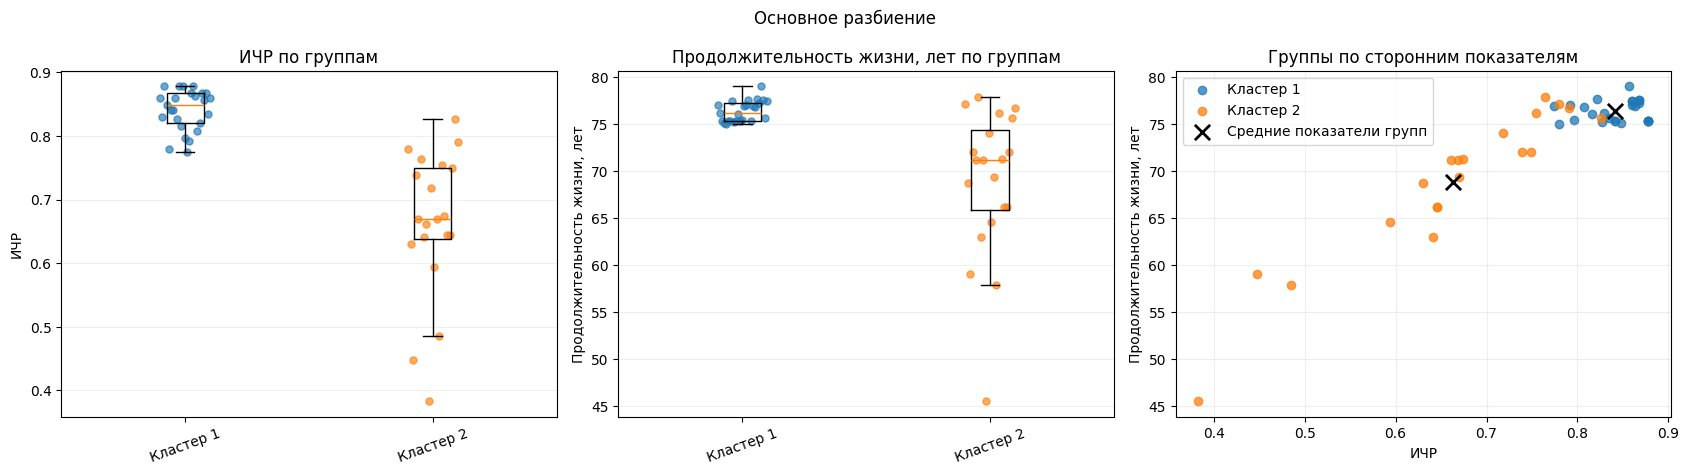

,Городов в оценке,Стран в оценке,η²: ИЧР,"η²: ИЧР, равный вес стран",η²: Продолжительность жизни,"η²: Продолжительность жизни, равный вес стран"
0,45,38,0.5563,0.4969,0.3414,0.3073


In [ ]:
# Сравниваем готовые группы по национальным показателям.
external_missing = attach_country_indicators(df)
print('Города без полного набора сторонних показателей:')
display(external_missing.loc[external_missing[external_features].isna().any(axis=1)])
external_main_result = compare_living_standards(df, df['Cluster'].to_numpy(), 'Основное разбиение')
display(pd.DataFrame([external_main_result]).round(4))


### Что показывает сравнение

В первом кластере средний ИЧР — **0,841**, продолжительность жизни — **76,4 года**; во втором — **0,663 и 68,8 года**. Разница составляет около **0,178 пункта ИЧР и 7,6 года**.

Разбиение на две группы выделяет общий контраст по уровню жизни.

Это не точная граница между странами с высоким и низким уровнем жизни. Диапазоны перекрываются; во второй группе ИЧР достигает 0,826, а продолжительность жизни — 77,9 года. Следовательно, исходные рабочее время, цены и зарплаты связаны с национальным уровнем жизни, но не описывают его полностью.


## Что если взять другое количество кластеров?

Давайте сравним разбиения на 3 и 4 кластера с исходным решением на 2 группы: профили, парные графики и устойчивость.


3 кластера: силуэт = 0.3612


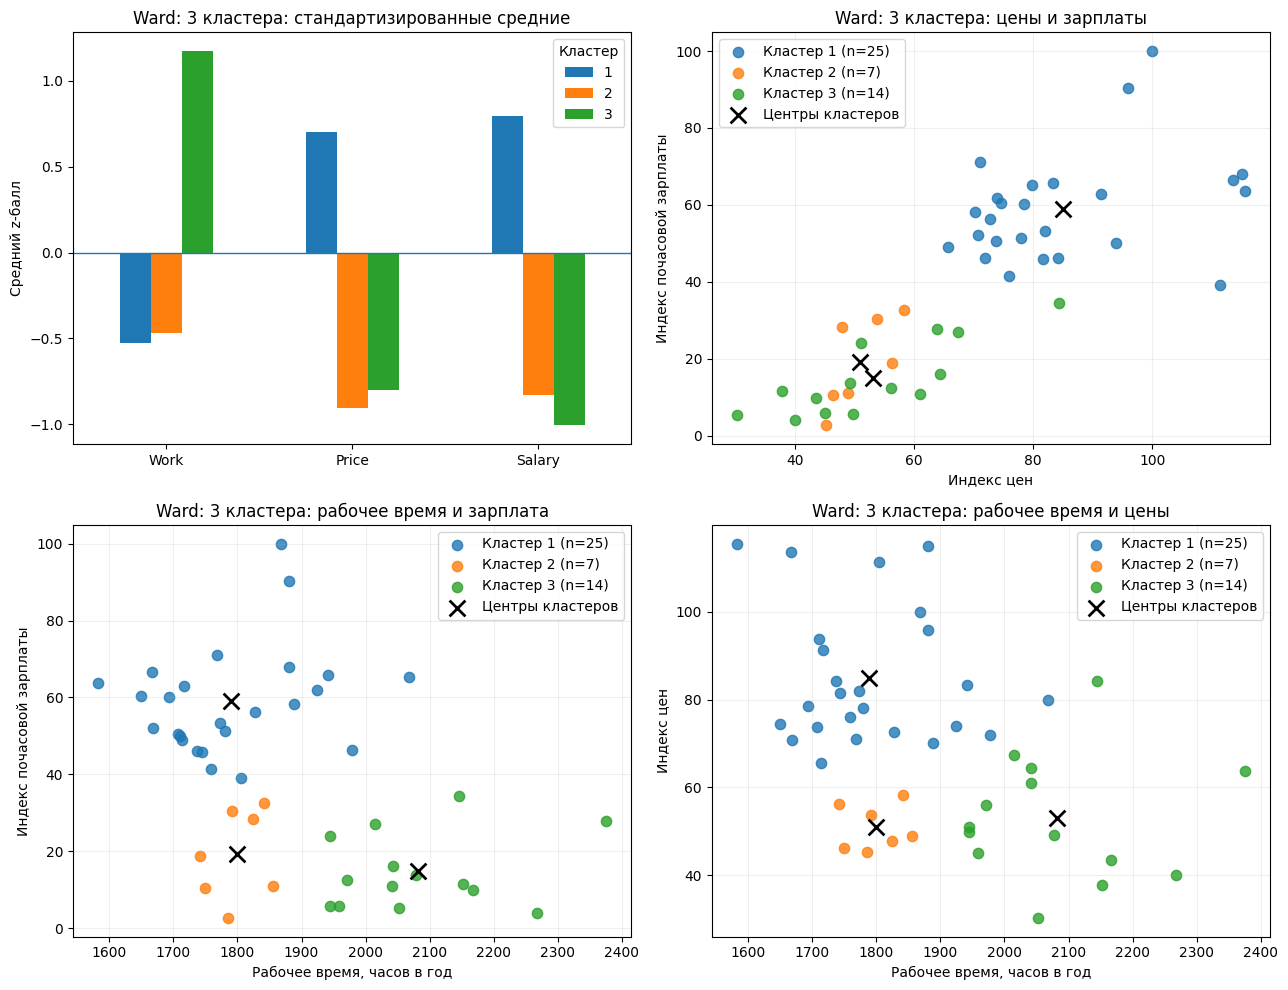

4 кластера: силуэт = 0.3551


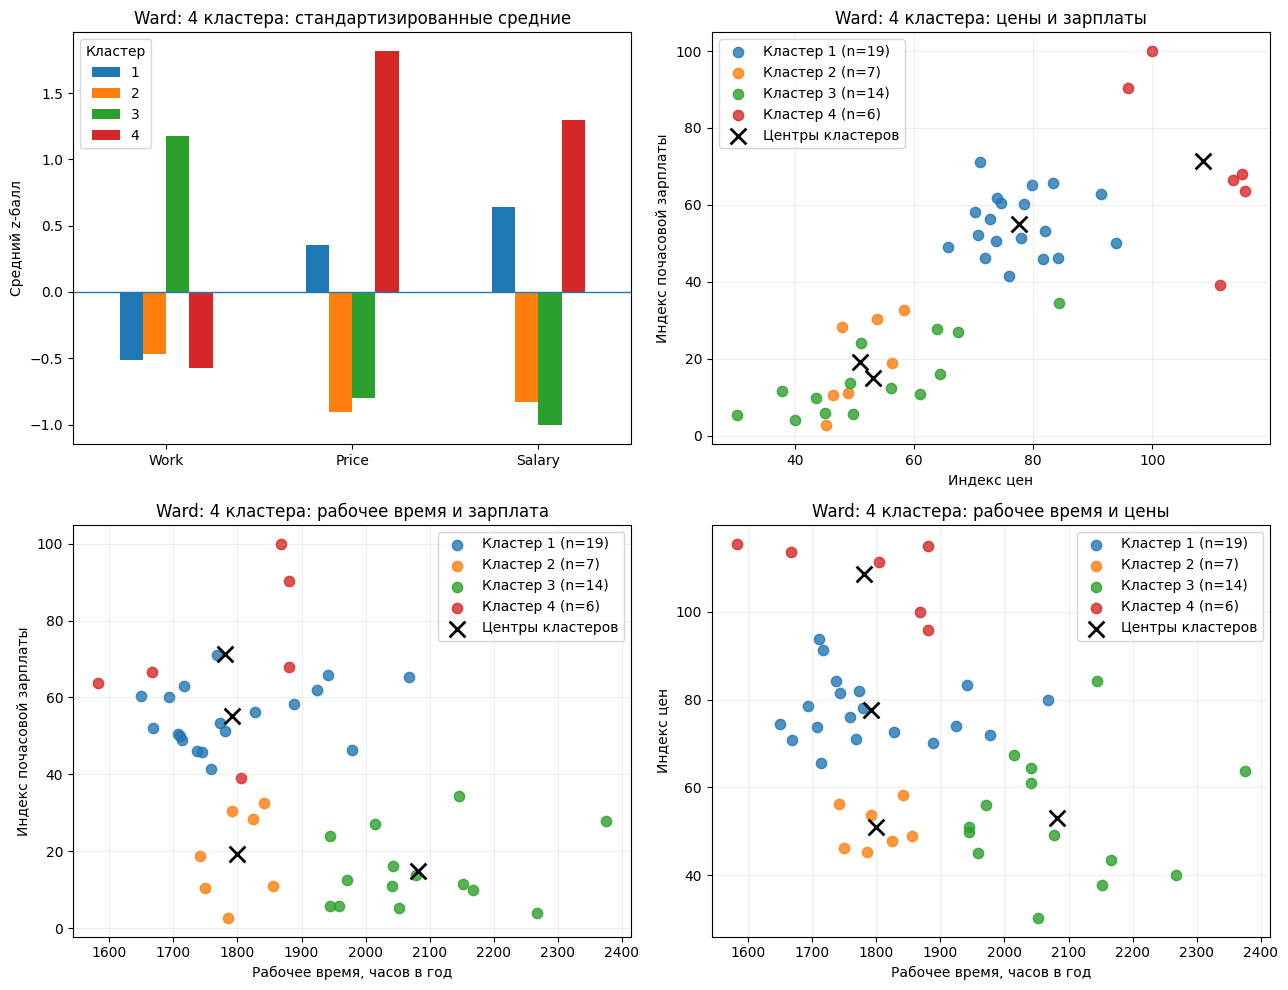

In [ ]:
# Строим профили и парные графики для трёх и четырёх групп.
for k in [3, 4]:
    alternative_labels = cut_tree(Z, n_clusters=k).ravel() + 1
    print(f'{k} кластера: силуэт = {silhouette_score(X, alternative_labels):.4f}')
    plot_cluster_profiles(df, X, alternative_labels, features, f'Ward: {k} кластера')


### Интерпретация кластеров

**При разбиении на 3 кластера:**

**Кластер 1 — 25 городов.** Например, Лондон, Нью-Йорк, Токио. Та же группа с большей почасовой оплатой и более высокими ценами при чуть меньшем количестве рабочих часов в год.

**Кластер 2 — 7 городов.** Например, Афины, Лиссабон, Сеул. ЗП и цены ниже, но работают примерно столько же, сколько в первом кластере.

**Кластер 3 — 14 городов.** Например, Мехико, Мумбаи, Гонконг. Цены примерно как во втором кластере, ЗП в среднем чуть ниже, а работают заметно больше.

**При разбиении на 4 кластера:**

**Кластер 1 — 19 городов.** Например, Лондон, Нью-Йорк, Париж. Почасовая оплата и цены выше, чем во втором и третьем кластерах, но ниже, чем в четвёртом.

**Кластер 2 — 7 городов.** Например, Афины, Лиссабон, Сеул. Та же группа с более низкими ЗП и ценами, без увеличенного количества рабочих часов.

**Кластер 3 — 14 городов.** Например, Мехико, Мумбаи, Гонконг. Та же группа с более низкими ЗП и большим количеством рабочих часов в год.

**Кластер 4 — 6 городов.** Например, Цюрих, Женева, Токио. Самые высокие средние цены и почасовая оплата. Работают примерно столько же, сколько в первом и втором кластерах.

**В целом разбиение на 3–4 группы менее чёткое и выглядит более шумным.** Например, второй и третий кластеры почти не отличаются по ценам и разделяются в основном по рабочему времени. Силуэт ниже, чем у двух групп, а при исключении отдельных городов состав кластеров чаще меняется. Получается более подробное, но более чувствительное разбиение.


### Как меняются группы и где размываются границы


Переход от двух групп к 3:


3 кластера,1,2,3
Два кластера,,,
1,25,0,0
2,0,7,14


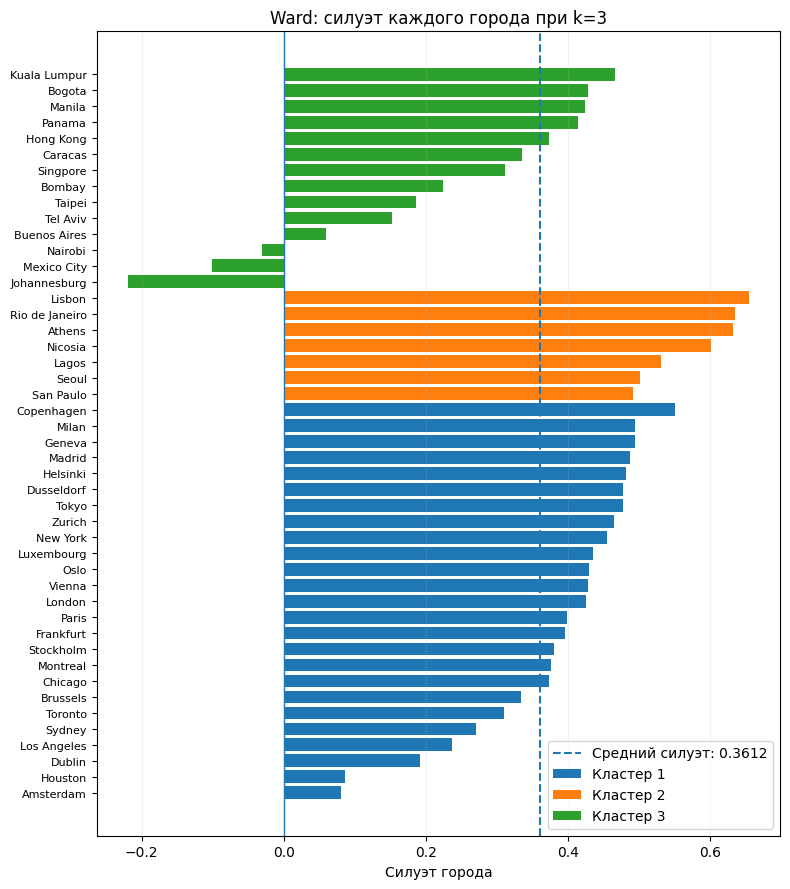

Городов с отрицательным силуэтом: 3
Города с силуэтом ниже 0,25:


,Город,Кластер,Силуэт
32,Johannesburg,3,-0.2197
33,Mexico_City,3,-0.1008
34,Nairobi,3,-0.0306
35,Buenos_Aires,3,0.0591
0,Amsterdam,1,0.0806
1,Houston,1,0.0868
36,Tel_Aviv,3,0.1522
37,Taipei,3,0.1860
2,Dublin,1,0.1919
38,Bombay,3,0.2244


Переход от двух групп к 4:


4 кластера,1,2,3,4
Два кластера,,,,
1,19,0,0,6
2,0,7,14,0


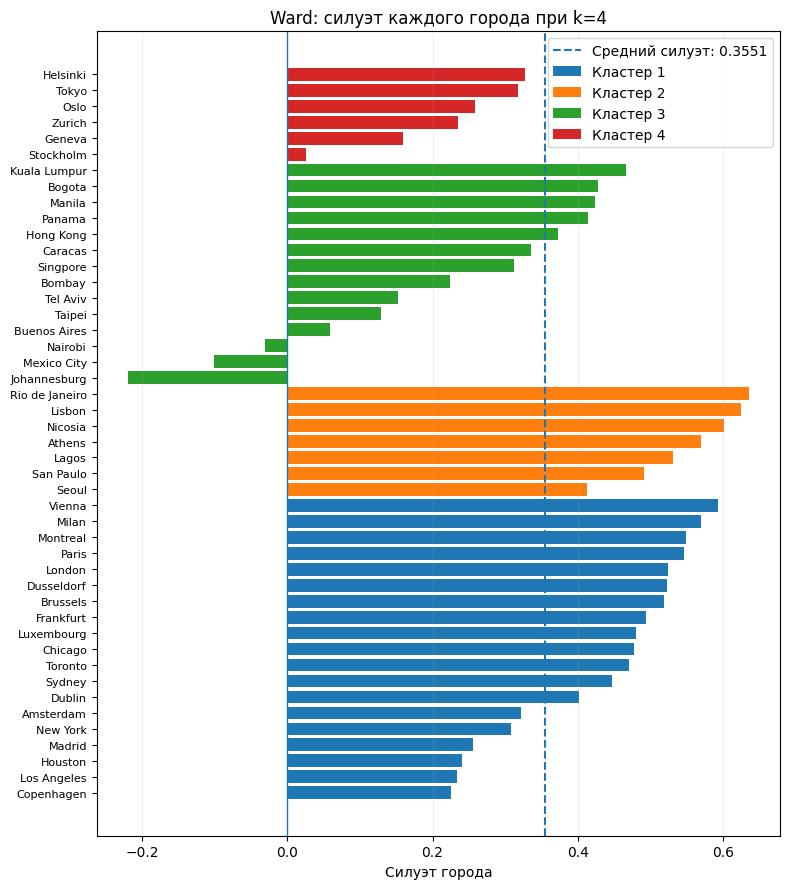

Городов с отрицательным силуэтом: 3
Города с силуэтом ниже 0,25:


,Город,Кластер,Силуэт
26,Johannesburg,3,-0.2197
27,Mexico_City,3,-0.1008
28,Nairobi,3,-0.0306
40,Stockholm,4,0.0255
29,Buenos_Aires,3,0.0591
30,Taipei,3,0.1285
31,Tel_Aviv,3,0.1522
41,Geneva,4,0.1592
32,Bombay,3,0.2244
0,Copenhagen,1,0.2249


In [ ]:
# Сравниваем состав исходных двух групп с разбиениями на три и четыре.
for k in [3, 4]:
    detailed_labels = cut_tree(Z, n_clusters=k).ravel() + 1
    print(f'Переход от двух групп к {k}:')
    display(pd.crosstab(pd.Series(labels, name='Два кластера'),
                        pd.Series(detailed_labels, name=f'{k} кластера')))
    # Показываем силуэты городов для нового разбиения.
    show_city_silhouette(X, detailed_labels, df.City,
                         f'Ward: силуэт каждого города при k={k}')


При переходе к трём группам исходные 25 городов остаются вместе, а группа из 21 города делится на 7 и 14. При четырёх группах из дорогих городов дополнительно выделяются 6. В обоих вариантах отрицательный силуэт у Йоханнесбурга, Мехико и Найроби: именно здесь проходит неудачная граница Ward.


### Сравнение чувствительности


Совпадение с Ward при смене метода:


method,average,complete,single,ward
k,,,,
2,1.0000,1.0000,0.0083,1.0
3,0.7875,0.8622,-0.0052,1.0
4,0.7599,0.8378,0.0778,1.0


Заполнение пропусков и исключение одного города:


,k,Силуэт,ARI после заполнения,Минимальный ARI при исключении,Медианный ARI при исключении,Полных совпадений из 46,Город с минимальным ARI
0,2,0.4705,1.0,0.6686,1.0,41,New_York
1,3,0.3612,1.0,0.4686,1.0,32,Singpore
2,4,0.3551,1.0,0.5686,1.0,32,Hong_Kong


Пять наиболее заметных изменений для каждого числа кластеров:


,Excluded_city,ARI,k
29,New_York,0.6686,2
43,Toronto,0.8263,2
37,Singpore,0.8263,2
7,Chicago,0.9111,2
14,Hong_Kong,0.9111,2
83,Singpore,0.4686,3
60,Hong_Kong,0.5398,3
47,Athens,0.5819,3
65,Lisbon,0.5819,3
76,Nicosia,0.5819,3


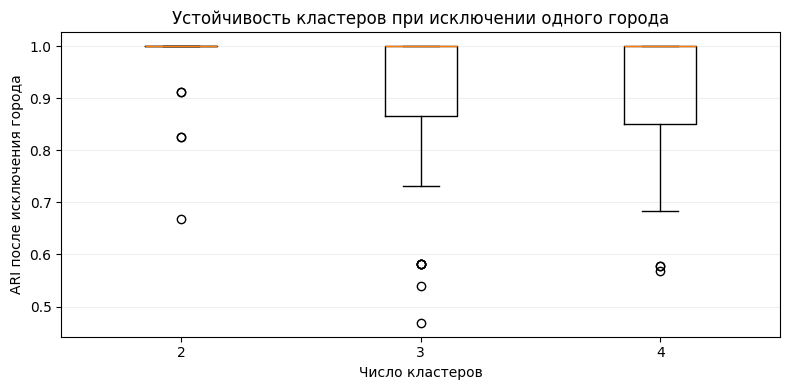

In [ ]:
agreement_rows = []
sensitivity_rows = []
loo_rows = []
# Проверяем разбиения на две, три и четыре группы.
for k in [2, 3, 4]:
    baseline = cut_tree(Z, n_clusters=k).ravel()
    for method in methods:
        other = cut_tree(links[method], n_clusters=k).ravel()
        agreement_rows.append({'k': k, 'method': method,
                               'ARI': adjusted_rand_score(baseline, other)})

    # Сравниваем назначения полных городов после заполнения пропусков.
    imputed = filled[['City']].assign(Cluster_imputed=cut_tree(Z_filled, n_clusters=k).ravel())
    common = df[['City']].assign(Cluster=baseline).merge(imputed, on='City', validate='one_to_one')
    imputation_ari = adjusted_rand_score(common.Cluster, common.Cluster_imputed)

    # Исключаем по одному городу и повторяем разбиение.
    if k not in loo_by_k:
        loo_by_k[k] = check_leave_one_out(
            df, features, baseline,
            lambda points: cut_tree(linkage(points, method='ward'), n_clusters=k).ravel())
    current_table = loo_by_k[k]
    current_loo = current_table.ARI.to_numpy()
    loo_rows.extend(current_table.assign(k=k).to_dict('records'))
    sensitivity_rows.append({
        'k': k, 'Силуэт': silhouette_score(X, baseline),
        'ARI после заполнения': imputation_ari,
        'Минимальный ARI при исключении': current_loo.min(),
        'Медианный ARI при исключении': np.median(current_loo),
        'Полных совпадений из 46': np.isclose(current_loo, 1).sum(),
        'Город с минимальным ARI': df.loc[current_loo.argmin(), 'City']})

# Сводим результаты проверок в таблицы.
agreement = pd.DataFrame(agreement_rows)
sensitivity = pd.DataFrame(sensitivity_rows)
loo = pd.DataFrame(loo_rows)
print('Совпадение с Ward при смене метода:')
display(agreement.pivot(index='k', columns='method', values='ARI').round(4))
print('Заполнение пропусков и исключение одного города:')
display(sensitivity.round(4))
print('Пять наиболее заметных изменений для каждого числа кластеров:')
display(loo.sort_values(['k', 'ARI', 'Excluded_city']).groupby('k').head(5).round(4))

# Показываем распределение изменений при исключении городов.
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([loo.loc[loo.k.eq(k), 'ARI'] for k in [2, 3, 4]])
ax.set(xticks=[1, 2, 3], xticklabels=['2', '3', '4'],
       xlabel='Число кластеров', ylabel='ARI после исключения города',
       title='Устойчивость кластеров при исключении одного города')
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

# Сохраняем результаты сравнения устойчивости.
sensitivity.to_csv('lab1_sensitivity_summary.csv', index=False, encoding='utf-8-sig')
loo.to_csv('lab1_sensitivity_leave_one_out.csv', index=False, encoding='utf-8-sig')


### Результаты сравнения

После медианного заполнения пропусков все три разбиения сохраняются (ARI = 1). При поочерёдном исключении городов состав групп сохраняется в 41 из 46 проверок для двух кластеров и в 32 из 46 для трёх и четырёх. Минимальный ARI: 0,6686 для двух групп (New York), 0,4686 для трёх (Singpore), 0,5686 для четырёх (Hong Kong). Медианный ARI во всех случаях равен 1.

При смене метода complete и average полностью совпадают с Ward только для двух групп. Для трёх и четырёх групп ARI составляет 0,76–0,86. В этих проверках разбиение на две группы устойчивее; три и четыре группы дают более подробное, но более чувствительное разделение.


### Сравнение разбиений по ИЧР и продолжительности жизни

Сопоставим те же города с известными национальными показателями при 2, 3 и 4 группах. Национальные показатели не участвуют в построении этих разбиений. Определение η² и источники данных приведены в разделе «Сравнение со сторонними показателями».


2 кластера
Городов с двумя показателями: 45/46; в кластерах: 45; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,25,19,0.841,0.848,0.774,0.878,76.395,76.192,75.025,79.037
Кластер 2,20,19,0.663,0.670,0.383,0.826,68.798,71.196,45.483,77.873


3 кластера
Городов с двумя показателями: 45/46; в кластерах: 45; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,25,19,0.841,0.848,0.774,0.878,76.395,76.192,75.025,79.037
Кластер 2,7,6,0.668,0.718,0.383,0.780,68.190,72.046,45.483,77.137
Кластер 3,13,13,0.661,0.669,0.448,0.826,69.125,71.172,57.826,77.873


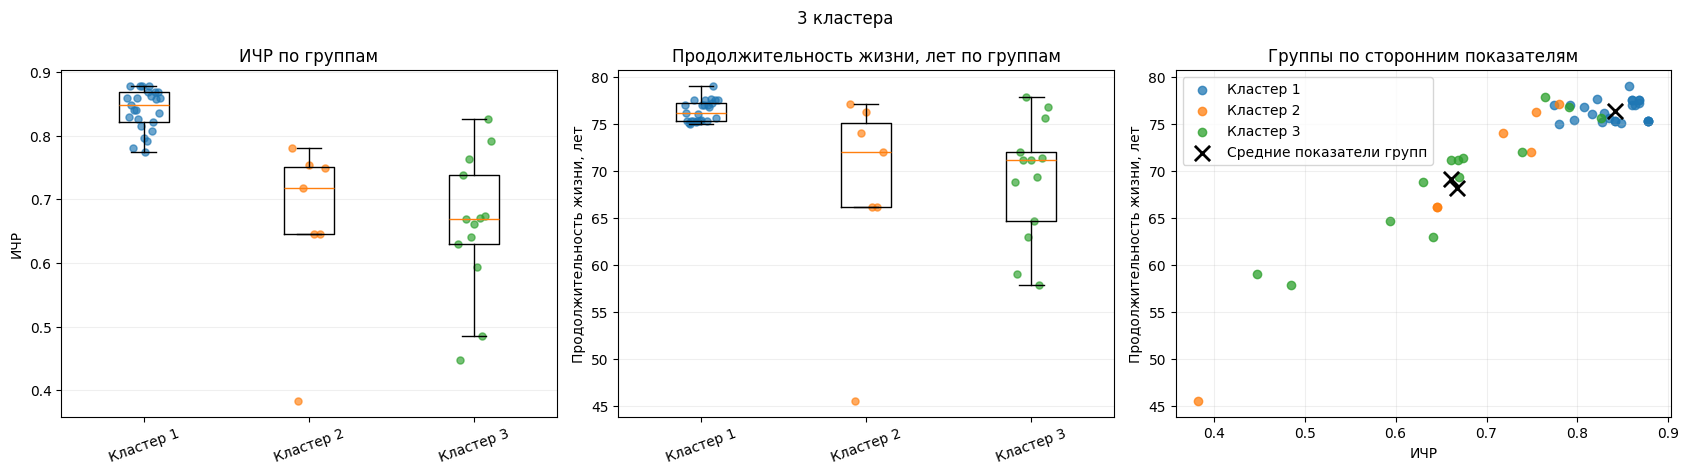

4 кластера
Городов с двумя показателями: 45/46; в кластерах: 45; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,19,14,0.839,0.841,0.774,0.878,76.102,75.617,75.025,77.593
Кластер 2,7,6,0.668,0.718,0.383,0.780,68.190,72.046,45.483,77.137
Кластер 3,13,13,0.661,0.669,0.448,0.826,69.125,71.172,57.826,77.873
Кластер 4,6,5,0.848,0.858,0.821,0.863,77.324,77.515,75.228,79.037


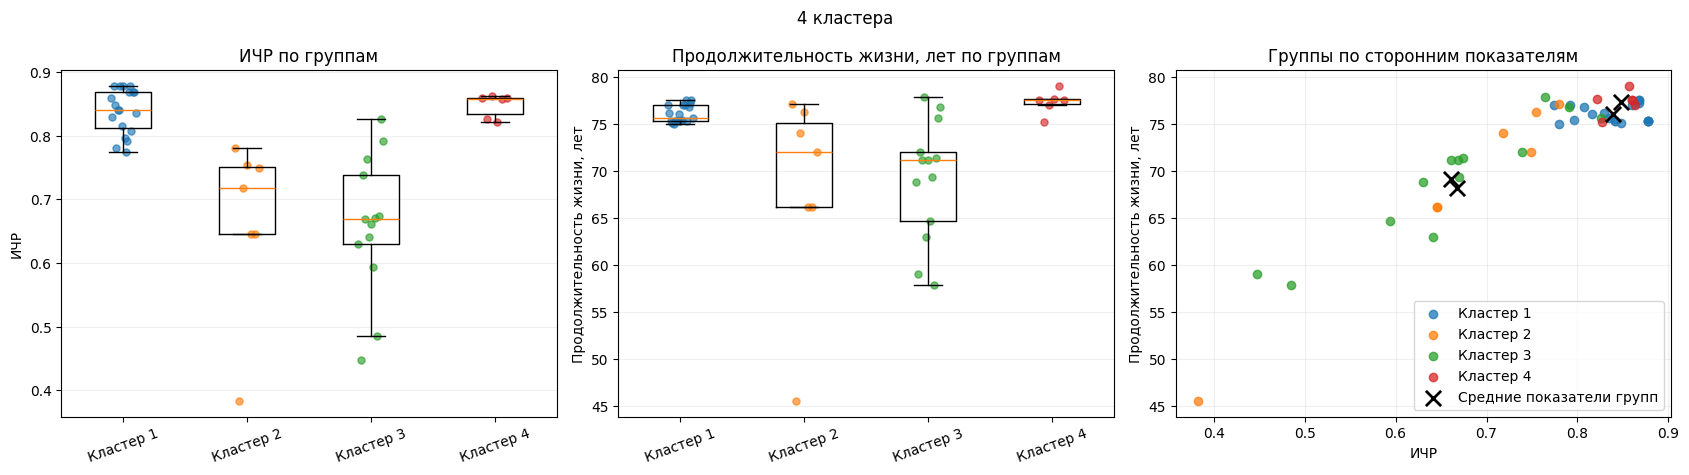

,Городов в оценке,Стран в оценке,η²: ИЧР,"η²: ИЧР, равный вес стран",η²: Продолжительность жизни,"η²: Продолжительность жизни, равный вес стран"
Кластеров,,,,,,
2,45,38,0.5563,0.4969,0.3414,0.3073
3,45,38,0.5567,0.4977,0.3435,0.3082
4,45,38,0.5573,0.4999,0.3471,0.3106


In [ ]:
# Сравниваем сторонние показатели при двух, трёх и четырёх группах.
external_k_rows = []
for k in [2, 3, 4]:
    alternative_external_labels = cut_tree(Z, n_clusters=k).ravel() + 1
    external_result = compare_living_standards(
        df, alternative_external_labels, f'{k} кластера', plots=k != 2)
    external_k_rows.append({'Кластеров': k, **external_result})
external_k_comparison = pd.DataFrame(external_k_rows).set_index('Кластеров')
display(external_k_comparison.round(4))


### Вывод по сторонним показателям

Видно, что при 3 и 4 кластерах показатели сильно более размытые и нельзя четко сказать, какую группу городов по качеству жизни описывает каждый кластер

